Correlation

Acoustic Top 7

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/Acoustic-subject-level-dataset_top7.csv')
df_acoustic_top7 = df_acoustic_top7.drop(columns=['Participant_ID'])
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(193, 8)
       RPDE  Degree-voice breaks  Delta2  Delta3  Delta11  MFCC5   spread1  \
0  0.428488                  0.0     0.0     0.0      0.0    0.0 -4.239926   
1  0.542488                  0.0     0.0     0.0      0.0    0.0 -4.519291   
2  0.332247                  0.0     0.0     0.0      0.0    0.0 -7.226125   
3  0.498593                  0.0     0.0     0.0      0.0    0.0 -5.632290   
4  0.470775                  0.0     0.0     0.0      0.0    0.0 -5.523149   

   Status  
0       1  
1       1  
2       0  
3       1  
4       1  


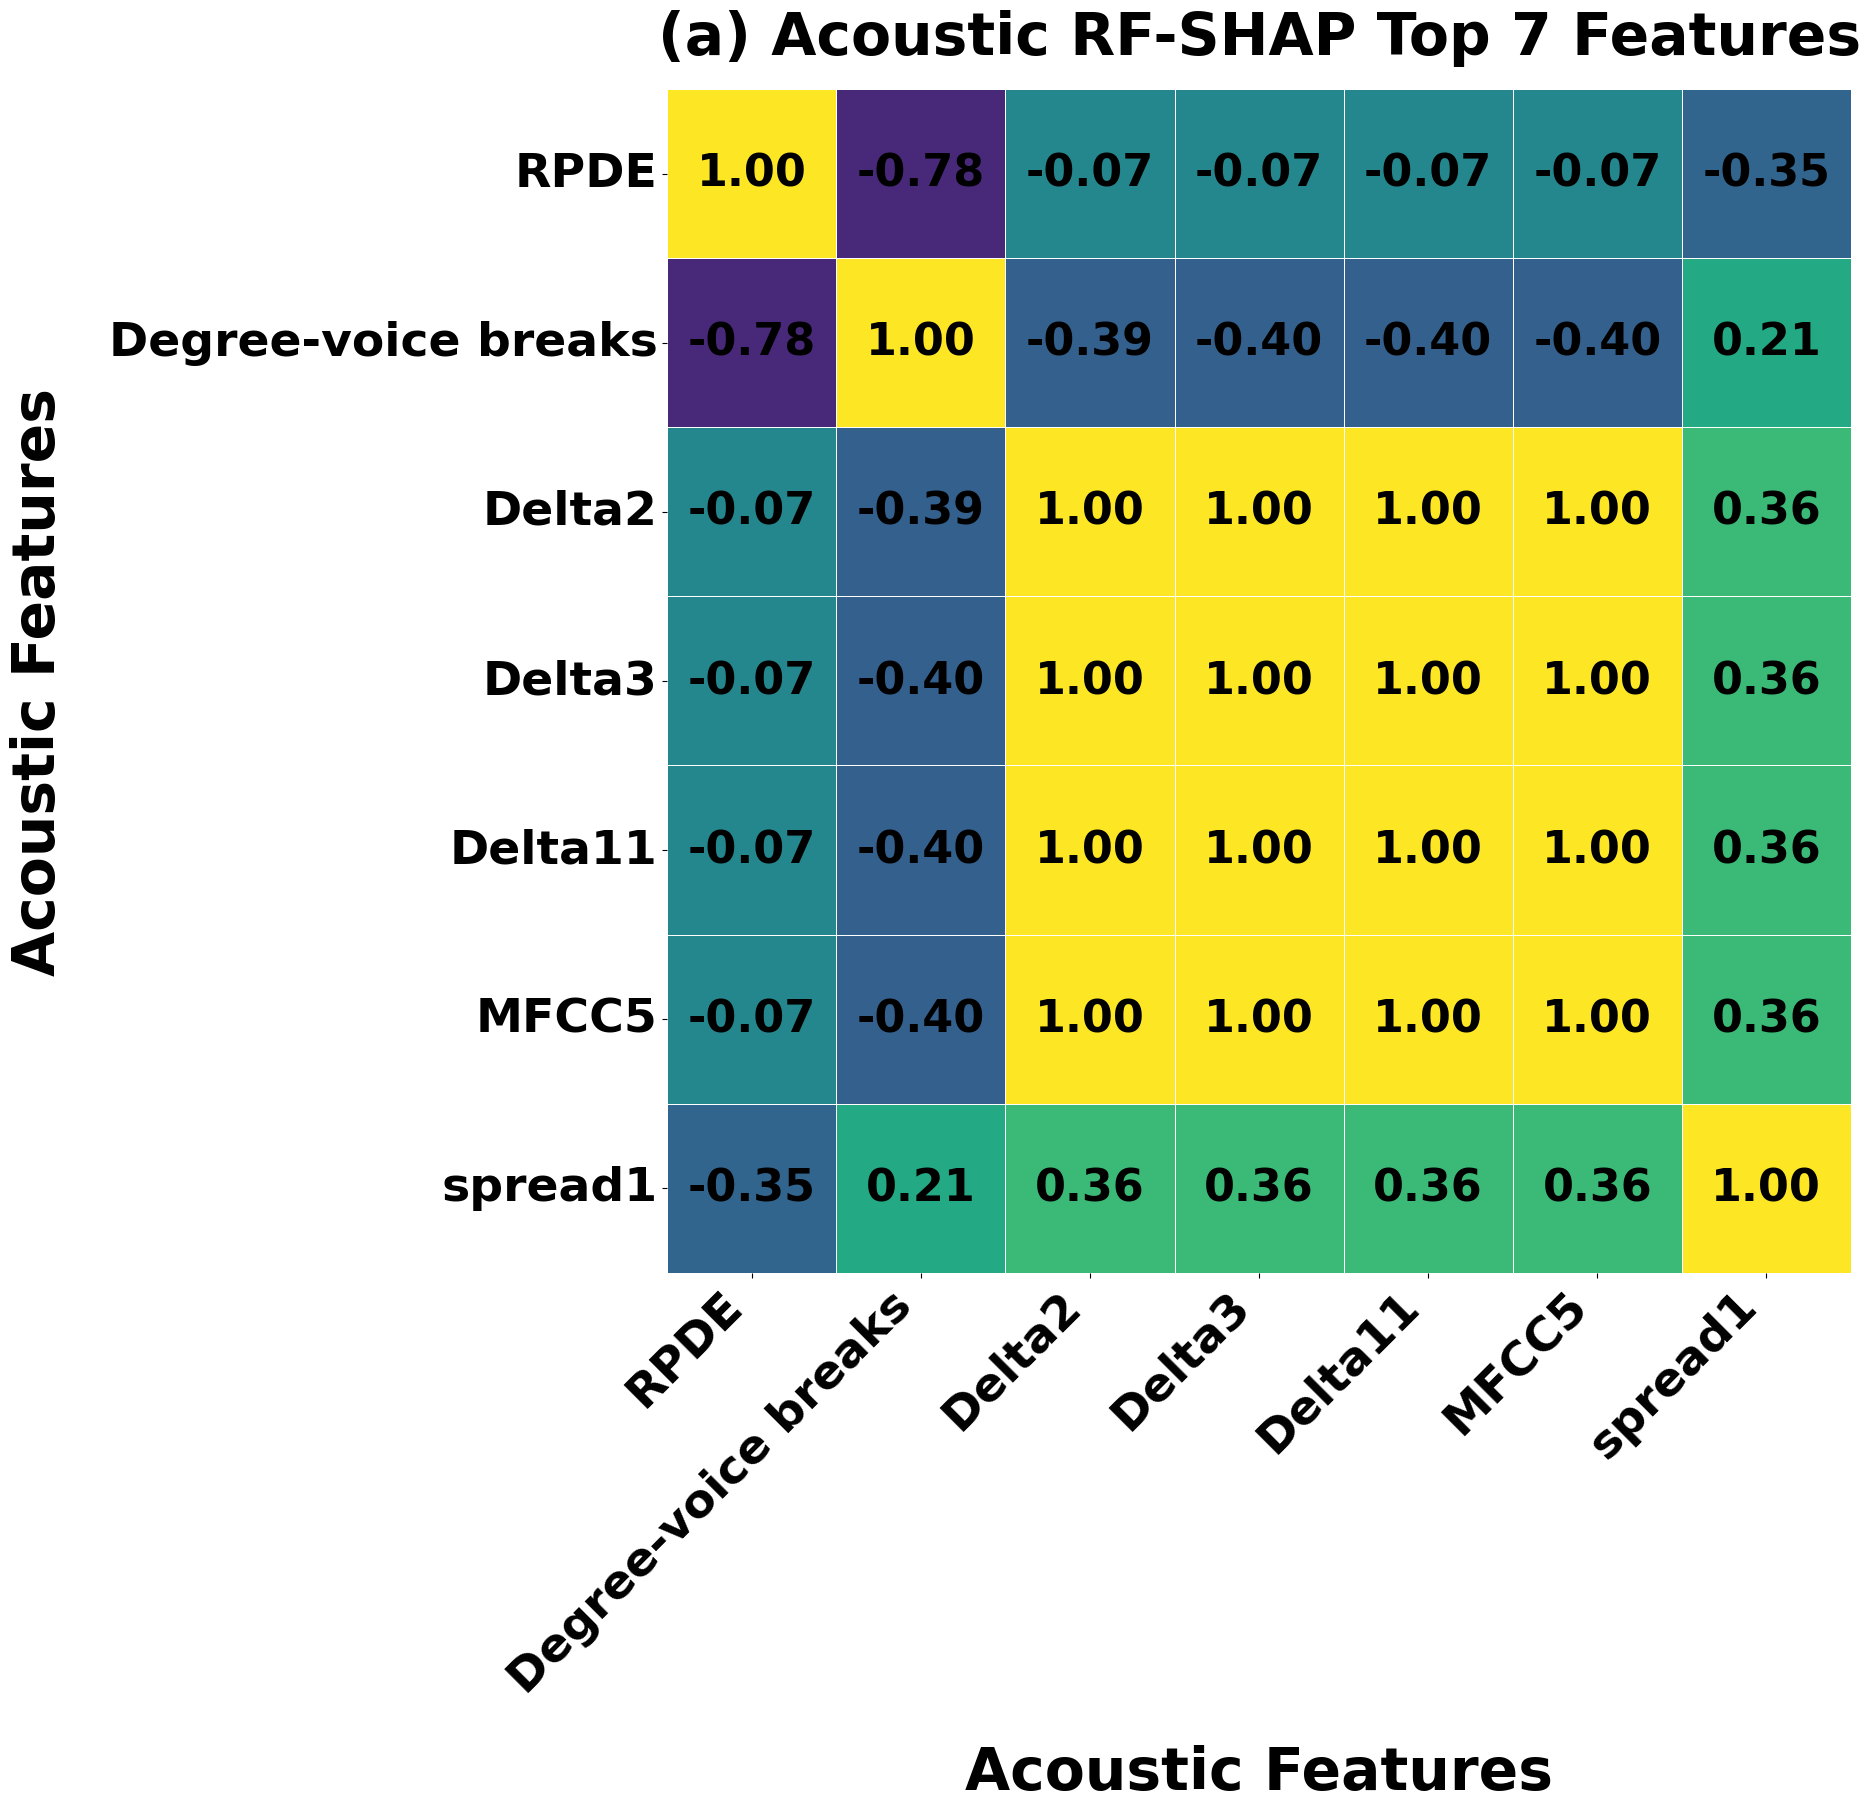

Saved Successfully!
/content/correlation_figures/a) Acoustic Top 7.svg
/content/correlation_figures/a) Acoustic Top 7.pdf


In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# Global plotting settings (IEEE JBHI Publication Style)
# ============================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# Acoustic features
# ============================================================
acoustic = df_acoustic_top7.iloc[:, :-1].copy()

# ============================================================
# Correlation matrix
# ============================================================
corr = acoustic.corr()
cross_corr = corr.loc[acoustic.columns]

# ============================================================
# Output folder
# ============================================================
FIG_DIR = "/content/correlation_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(
    figsize=(20, 18),
    constrained_layout=True
)

sns.heatmap(
    cross_corr,
    annot=True,
    fmt=".2f",

    # Light diverging color palette
    cmap="viridis",

    # Fixed correlation range
    center=0,
    vmin=-1,
    vmax=1,

    # Heatmap appearance
    square=True,
    linewidths=0.7,
    linecolor="white",

    # No colorbar
    cbar=False,

    # Annotation settings
    annot_kws={
        "size": 32,
        "weight": "semibold",
        "color": "black"
    },

    ax=ax
)

# ============================================================
# Tick labels
# ============================================================
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=34,
    fontweight="semibold"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=34,
    fontweight="semibold"
)

# ============================================================
# Axis labels
# ============================================================
ax.set_xlabel(
    "Acoustic Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

ax.set_ylabel(
    "Acoustic Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

# ============================================================
# Title
# ============================================================
ax.set_title(
    "(a) Acoustic RF-SHAP Top 7 Features",
    fontsize=42,
    fontweight="bold",
    pad=25
)

# ============================================================
# Save Figure
# ============================================================
svg_path = os.path.join(
    FIG_DIR, "a) Acoustic Top 7.svg"
)

pdf_path = os.path.join(
    FIG_DIR, "a) Acoustic Top 7.pdf"
)

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print("Saved Successfully!")
print(svg_path)
print(pdf_path)

In [10]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

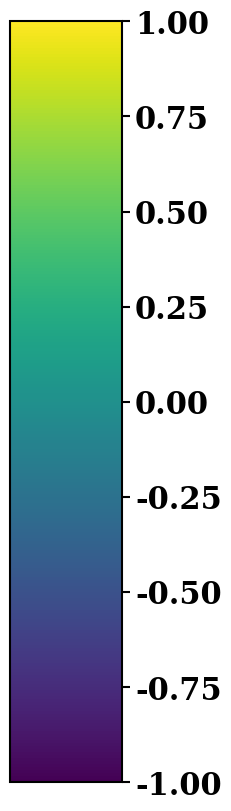

Saved Successfully!
/content/correlation_figures/Correlation_Colorbar.svg
/content/correlation_figures/Correlation_Colorbar.pdf


In [13]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FormatStrFormatter
import os

# ============================================================
# Global plotting settings (IEEE JBHI Publication Style)
# ============================================================
plt.rcParams["font.family"] = "serif"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# Output folder
# ============================================================
FIG_DIR = "/content/correlation_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Figure
# ============================================================
fig, ax = plt.subplots(
    figsize=(2.2, 8),
    constrained_layout=True
)

# ============================================================
# Colorbar
# ============================================================
norm = mpl.colors.Normalize(
    vmin=-1.0,
    vmax=1.0
)

cmap = plt.get_cmap("viridis")

cb = mpl.colorbar.ColorbarBase(
    ax,
    cmap=cmap,
    norm=norm,
    orientation="vertical"
)

# ============================================================
# Exact tick positions
# ============================================================
cb.set_ticks([
    -1.00,
    -0.75,
    -0.50,
    -0.25,
     0.00,
     0.25,
     0.50,
     0.75,
     1.00
])

# ============================================================
# Tick formatting: ALWAYS two decimal places
# ============================================================
cb.ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cb.ax.tick_params(
    labelsize=22,
    width=1.5,
    length=6
)

for tick in cb.ax.get_yticklabels():
    tick.set_fontweight("semibold")

# ============================================================
# Border thickness
# ============================================================
cb.outline.set_linewidth(1.5)

# ============================================================
# Save
# ============================================================
svg_path = os.path.join(
    FIG_DIR,
    "Correlation_Colorbar.svg"
)

pdf_path = os.path.join(
    FIG_DIR,
    "Correlation_Colorbar.pdf"
)

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print("Saved Successfully!")
print(svg_path)
print(pdf_path)

In [14]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Meg-Rest

In [2]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/final_meg-rest(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())

Loaded data shape: (127, 8)
   ibi_cv_asym  ibi_cv_L_std  mean_burst_duration_R_std  \
0     0.002893      0.048081                   0.002407   
1    -0.018062      0.085531                   0.005160   
2    -0.002573      0.032173                   0.001270   
3     0.001531      0.044880                   0.003106   
4     0.023834      0.142267                   0.004734   

   mean_burst_duration_asym  burst_dur_cv_R_std  burst_dur_cv_L_std  \
0                  0.009156            0.040693            0.055777   
1                 -0.005581            0.048648            0.052883   
2                  0.007325            0.030995            0.046488   
3                  0.005372            0.042429            0.049082   
4                  0.014897            0.044595            0.053040   

   ibi_cv_R_std  PD_Label_Combined  
0      0.043907                  0  
1      0.086747                  0  
2      0.032718                  0  
3      0.044973                  1  
4    

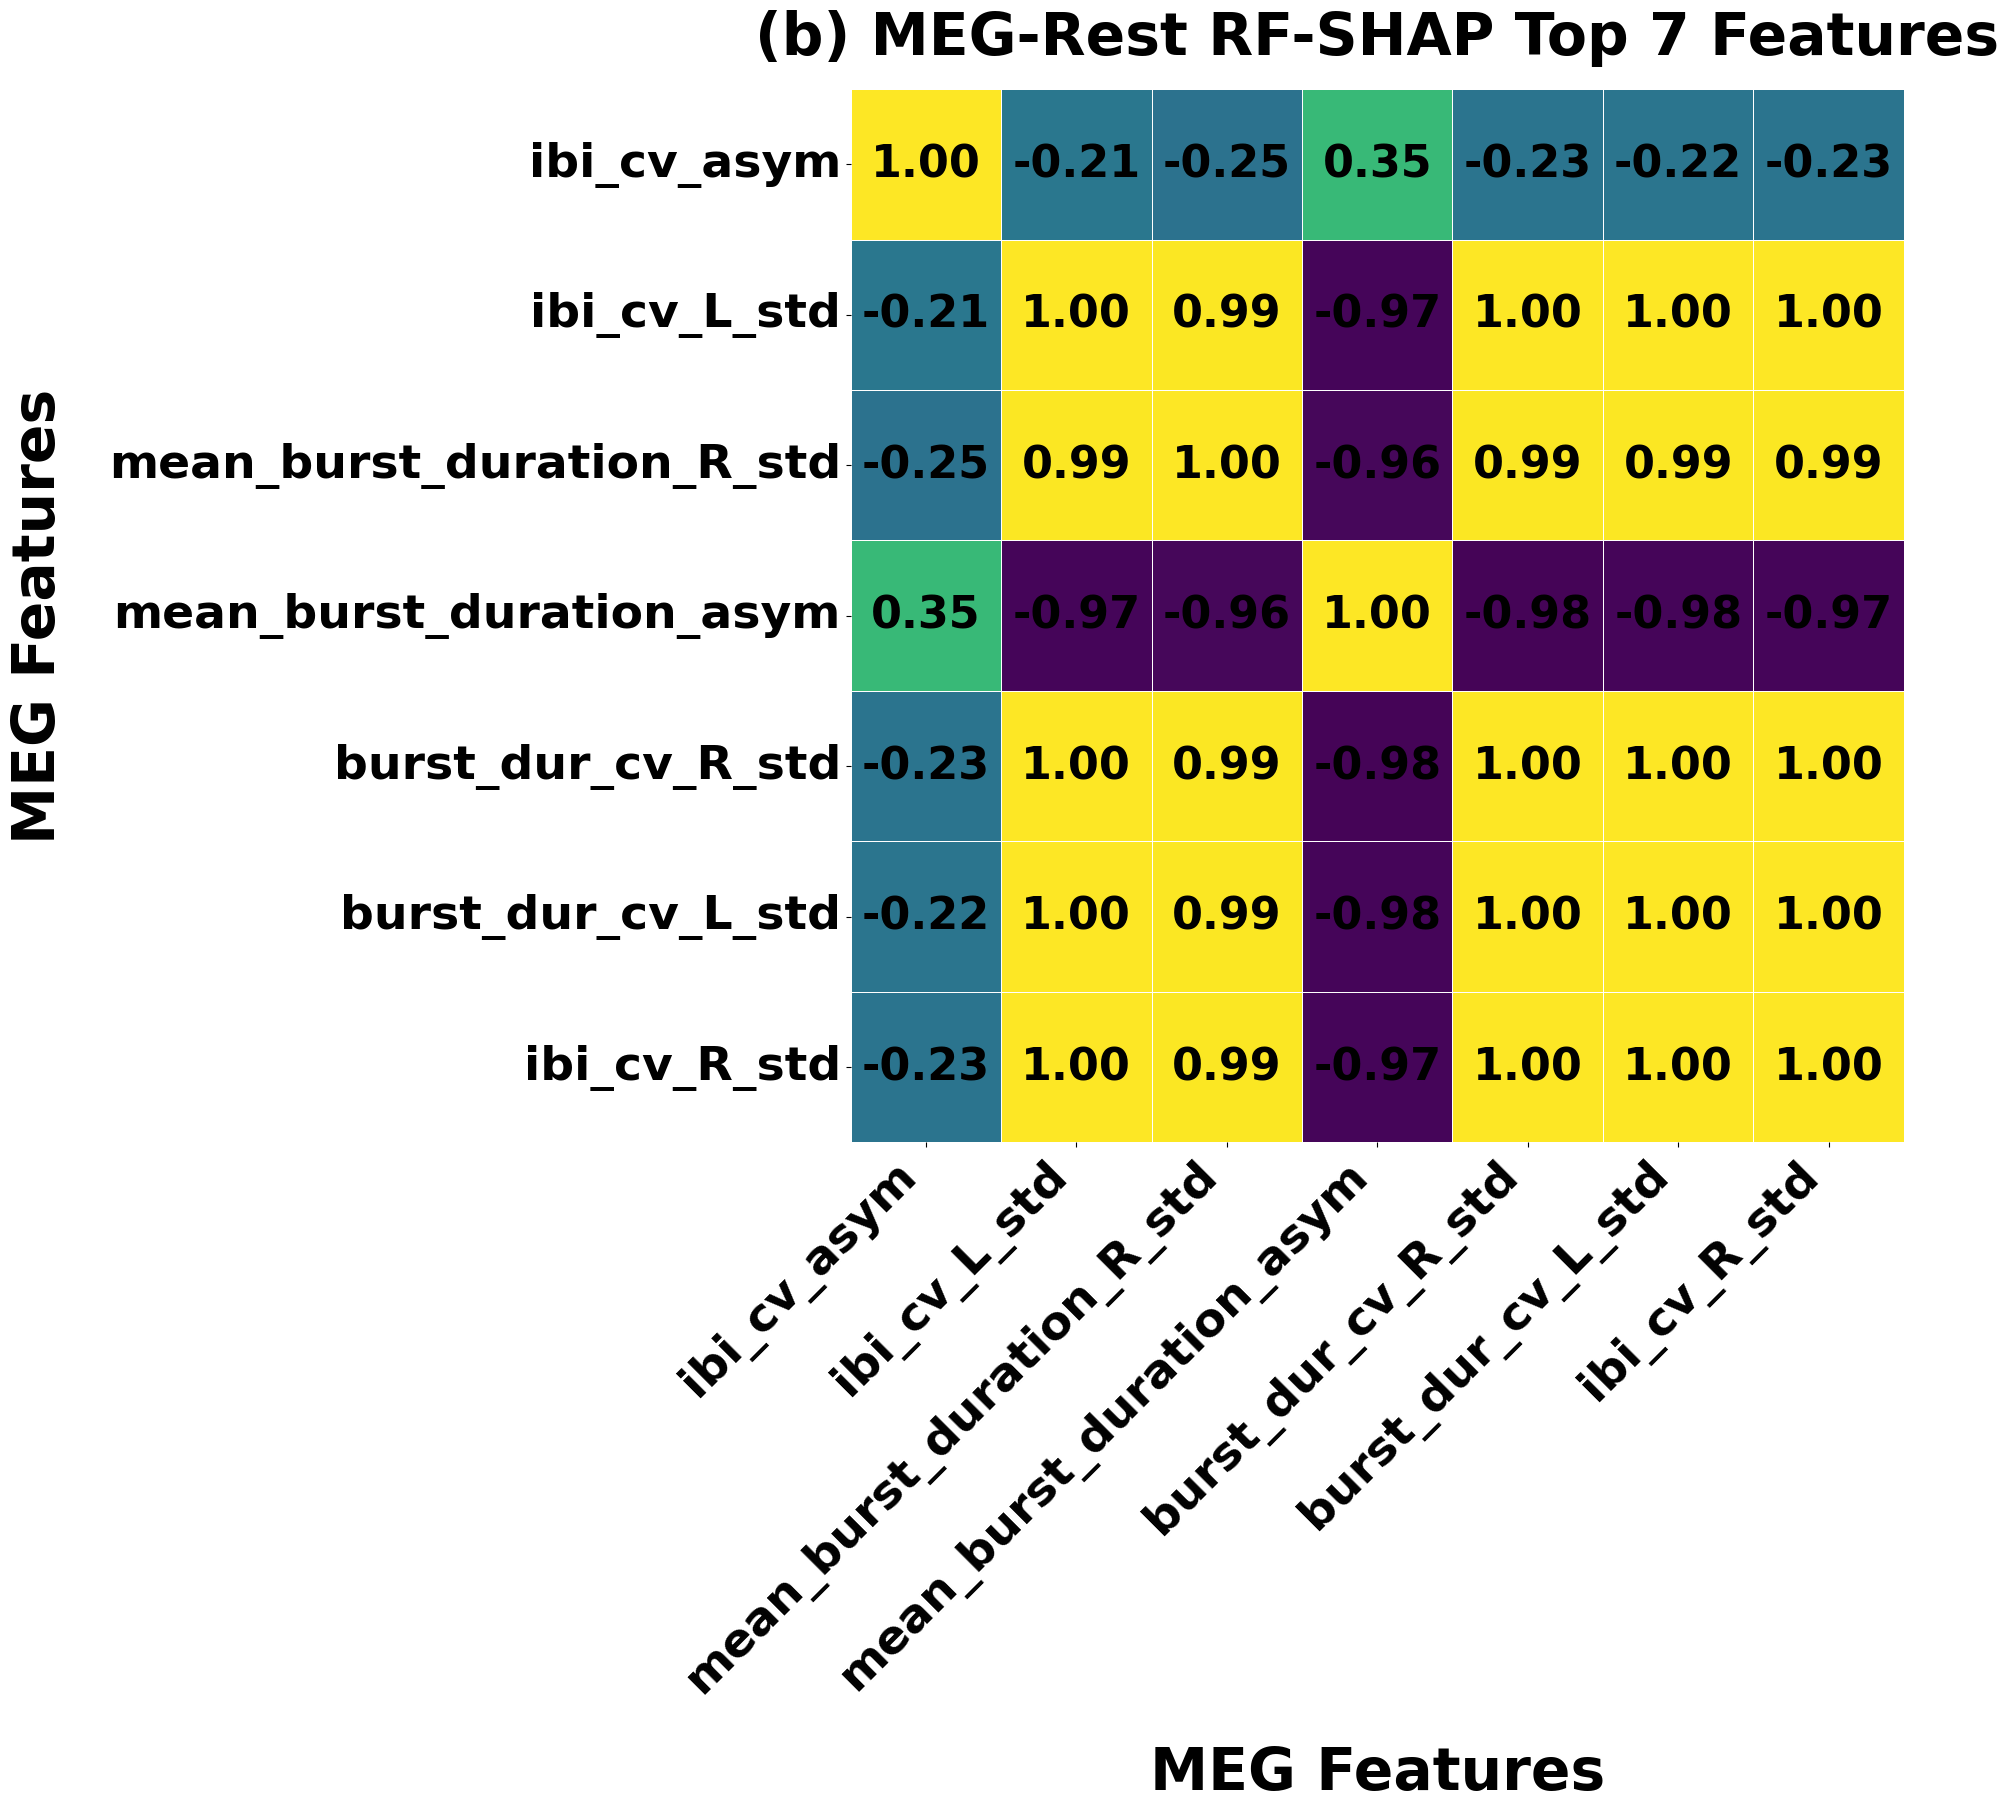

Saved Successfully!
/content/correlation_figures/a) MEG-Rest Top 7.svg
/content/correlation_figures/a) MEG-Rest Top 7.pdf


In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# Global plotting settings (IEEE JBHI Publication Style)
# ============================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# meg features
# ============================================================
meg = final_meg_df.iloc[:, :-1].copy()

# ============================================================
# Correlation matrix
# ============================================================
corr = meg.corr()
cross_corr = corr.loc[meg.columns]

# ============================================================
# Output folder
# ============================================================
FIG_DIR = "/content/correlation_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(
    figsize=(20, 18),
    constrained_layout=True
)

sns.heatmap(
    cross_corr,
    annot=True,
    fmt=".2f",

    # Light diverging color palette
    cmap="viridis",

    # Fixed correlation range
    center=0,
    vmin=-1,
    vmax=1,

    # Heatmap appearance
    square=True,
    linewidths=0.7,
    linecolor="white",

    # No colorbar
    cbar=False,

    # Annotation settings
    annot_kws={
        "size": 32,
        "weight": "semibold",
        "color": "black"
    },

    ax=ax
)

# ============================================================
# Tick labels
# ============================================================
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=34,
    fontweight="semibold"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=34,
    fontweight="semibold"
)

# ============================================================
# Axis labels
# ============================================================
ax.set_xlabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

ax.set_ylabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

# ============================================================
# Title
# ============================================================
ax.set_title(
    "(b) MEG-Rest RF-SHAP Top 7 Features",
    fontsize=42,
    fontweight="bold",
    pad=25
)

# ============================================================
# Save Figure
# ============================================================
svg_path = os.path.join(
    FIG_DIR, "a) MEG-Rest Top 7.svg"
)

pdf_path = os.path.join(
    FIG_DIR, "a) MEG-Rest Top 7.pdf"
)

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print("Saved Successfully!")
print(svg_path)
print(pdf_path)

In [6]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Meg-Go

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/final_meg-go(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())


Loaded data shape: (127, 8)
   env_kurt_R_mean  env_kurt_R_std  env_kurt_L_mean  env_kurt_L_std  \
0         5.749049       15.894836         5.962378       17.165772   
1         4.459546        7.184608         4.390848        6.578943   
2         1.161476        0.718562         1.885349        1.714298   
3         1.138575        0.699601         1.365950        0.817770   
4     18283.789736     4480.567058     18277.357293     4487.602704   

   burst_dur_cv_L_std  env_mod_rate_L_std  env_skew_L_mean  PD_Label_Combined  
0        4.938551e-02            0.244843         1.123760                  0  
1        1.147524e-01            0.117228         1.400286                  0  
2        5.040195e-02            0.275503         0.953293                  0  
3        4.311462e-02            0.460356         0.920828                  1  
4        1.043683e-16            0.064449       129.243639                  1  


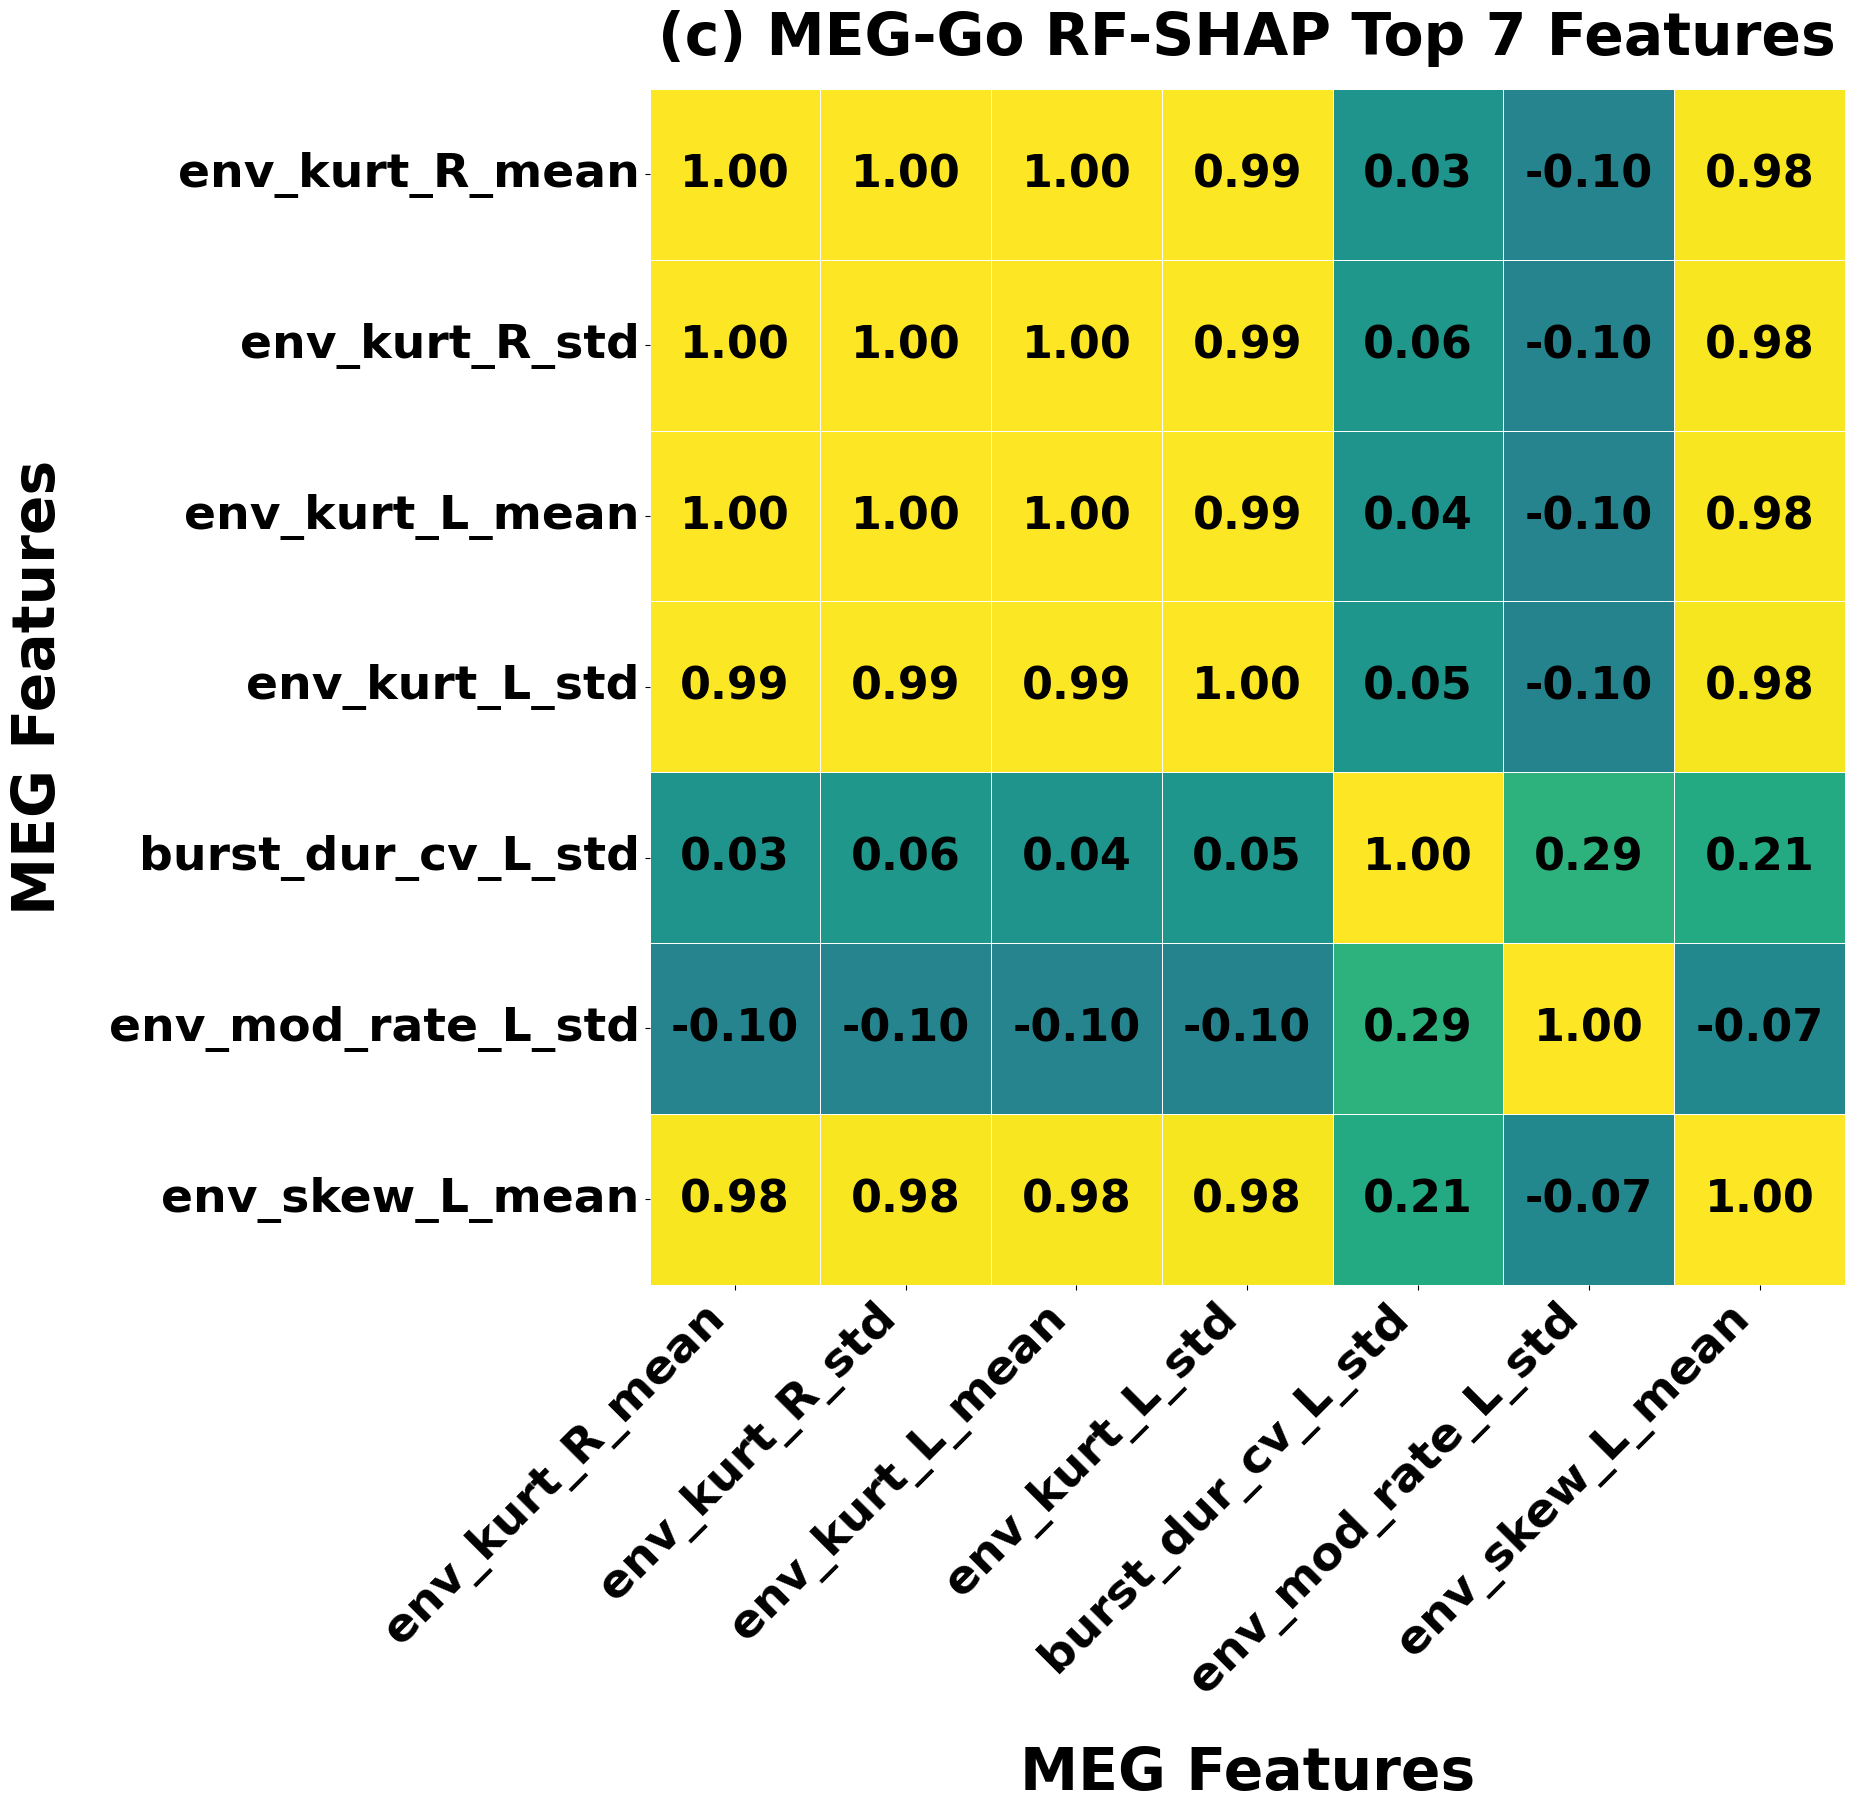

Saved Successfully!
/content/correlation_figures/a) MEG-Go Top 7.svg
/content/correlation_figures/a) MEG-Go Top 7.pdf


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# Global plotting settings (IEEE JBHI Publication Style)
# ============================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# meg features
# ============================================================
meg = final_meg_df.iloc[:, :-1].copy()

# ============================================================
# Correlation matrix
# ============================================================
corr = meg.corr()
cross_corr = corr.loc[meg.columns]

# ============================================================
# Output folder
# ============================================================
FIG_DIR = "/content/correlation_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(
    figsize=(20, 18),
    constrained_layout=True
)

sns.heatmap(
    cross_corr,
    annot=True,
    fmt=".2f",

    # Light diverging color palette
    cmap="viridis",

    # Fixed correlation range
    center=0,
    vmin=-1,
    vmax=1,

    # Heatmap appearance
    square=True,
    linewidths=0.7,
    linecolor="white",

    # No colorbar
    cbar=False,

    # Annotation settings
    annot_kws={
        "size": 32,
        "weight": "semibold",
        "color": "black"
    },

    ax=ax
)

# ============================================================
# Tick labels
# ============================================================
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=34,
    fontweight="semibold"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=34,
    fontweight="semibold"
)

# ============================================================
# Axis labels
# ============================================================
ax.set_xlabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

ax.set_ylabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

# ============================================================
# Title
# ============================================================
ax.set_title(
    "(c) MEG-Go RF-SHAP Top 7 Features",
    fontsize=42,
    fontweight="bold",
    pad=25
)

# ============================================================
# Save Figure
# ============================================================
svg_path = os.path.join(
    FIG_DIR, "a) MEG-Go Top 7.svg"
)

pdf_path = os.path.join(
    FIG_DIR, "a) MEG-Go Top 7.pdf"
)

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print("Saved Successfully!")
print(svg_path)
print(pdf_path)

In [4]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Meg-Passive

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

final_meg_df = pd.read_csv('/content/drive/MyDrive/final_meg-passive(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_df.shape)
print(final_meg_df.head())

Loaded data shape: (127, 8)
   env_kurt_asym  burst_amp_cv_asym  env_kurt_R_mean  env_mod_rate_L_std  \
0      -0.076816           0.013925         2.510726            0.296017   
1      -0.053170          -0.011675         2.189911            0.076190   
2       0.073234           0.010955         1.217854            0.413152   
3       0.077393           0.027533         1.394646            0.467633   
4       0.022059           0.005688         1.268945            0.309523   

   env_mod_rate_R_std  mean_burst_duration_R_std  env_mod_rate_R_mean  \
0            0.312178                   0.002180             0.421821   
1            0.063898                   0.012065             0.208876   
2            0.278854                   0.001874             0.462511   
3            0.511813                   0.003089             0.637478   
4            0.341810                   0.004726             0.295681   

   PD_Label_Combined  
0                  0  
1                  0  
2      

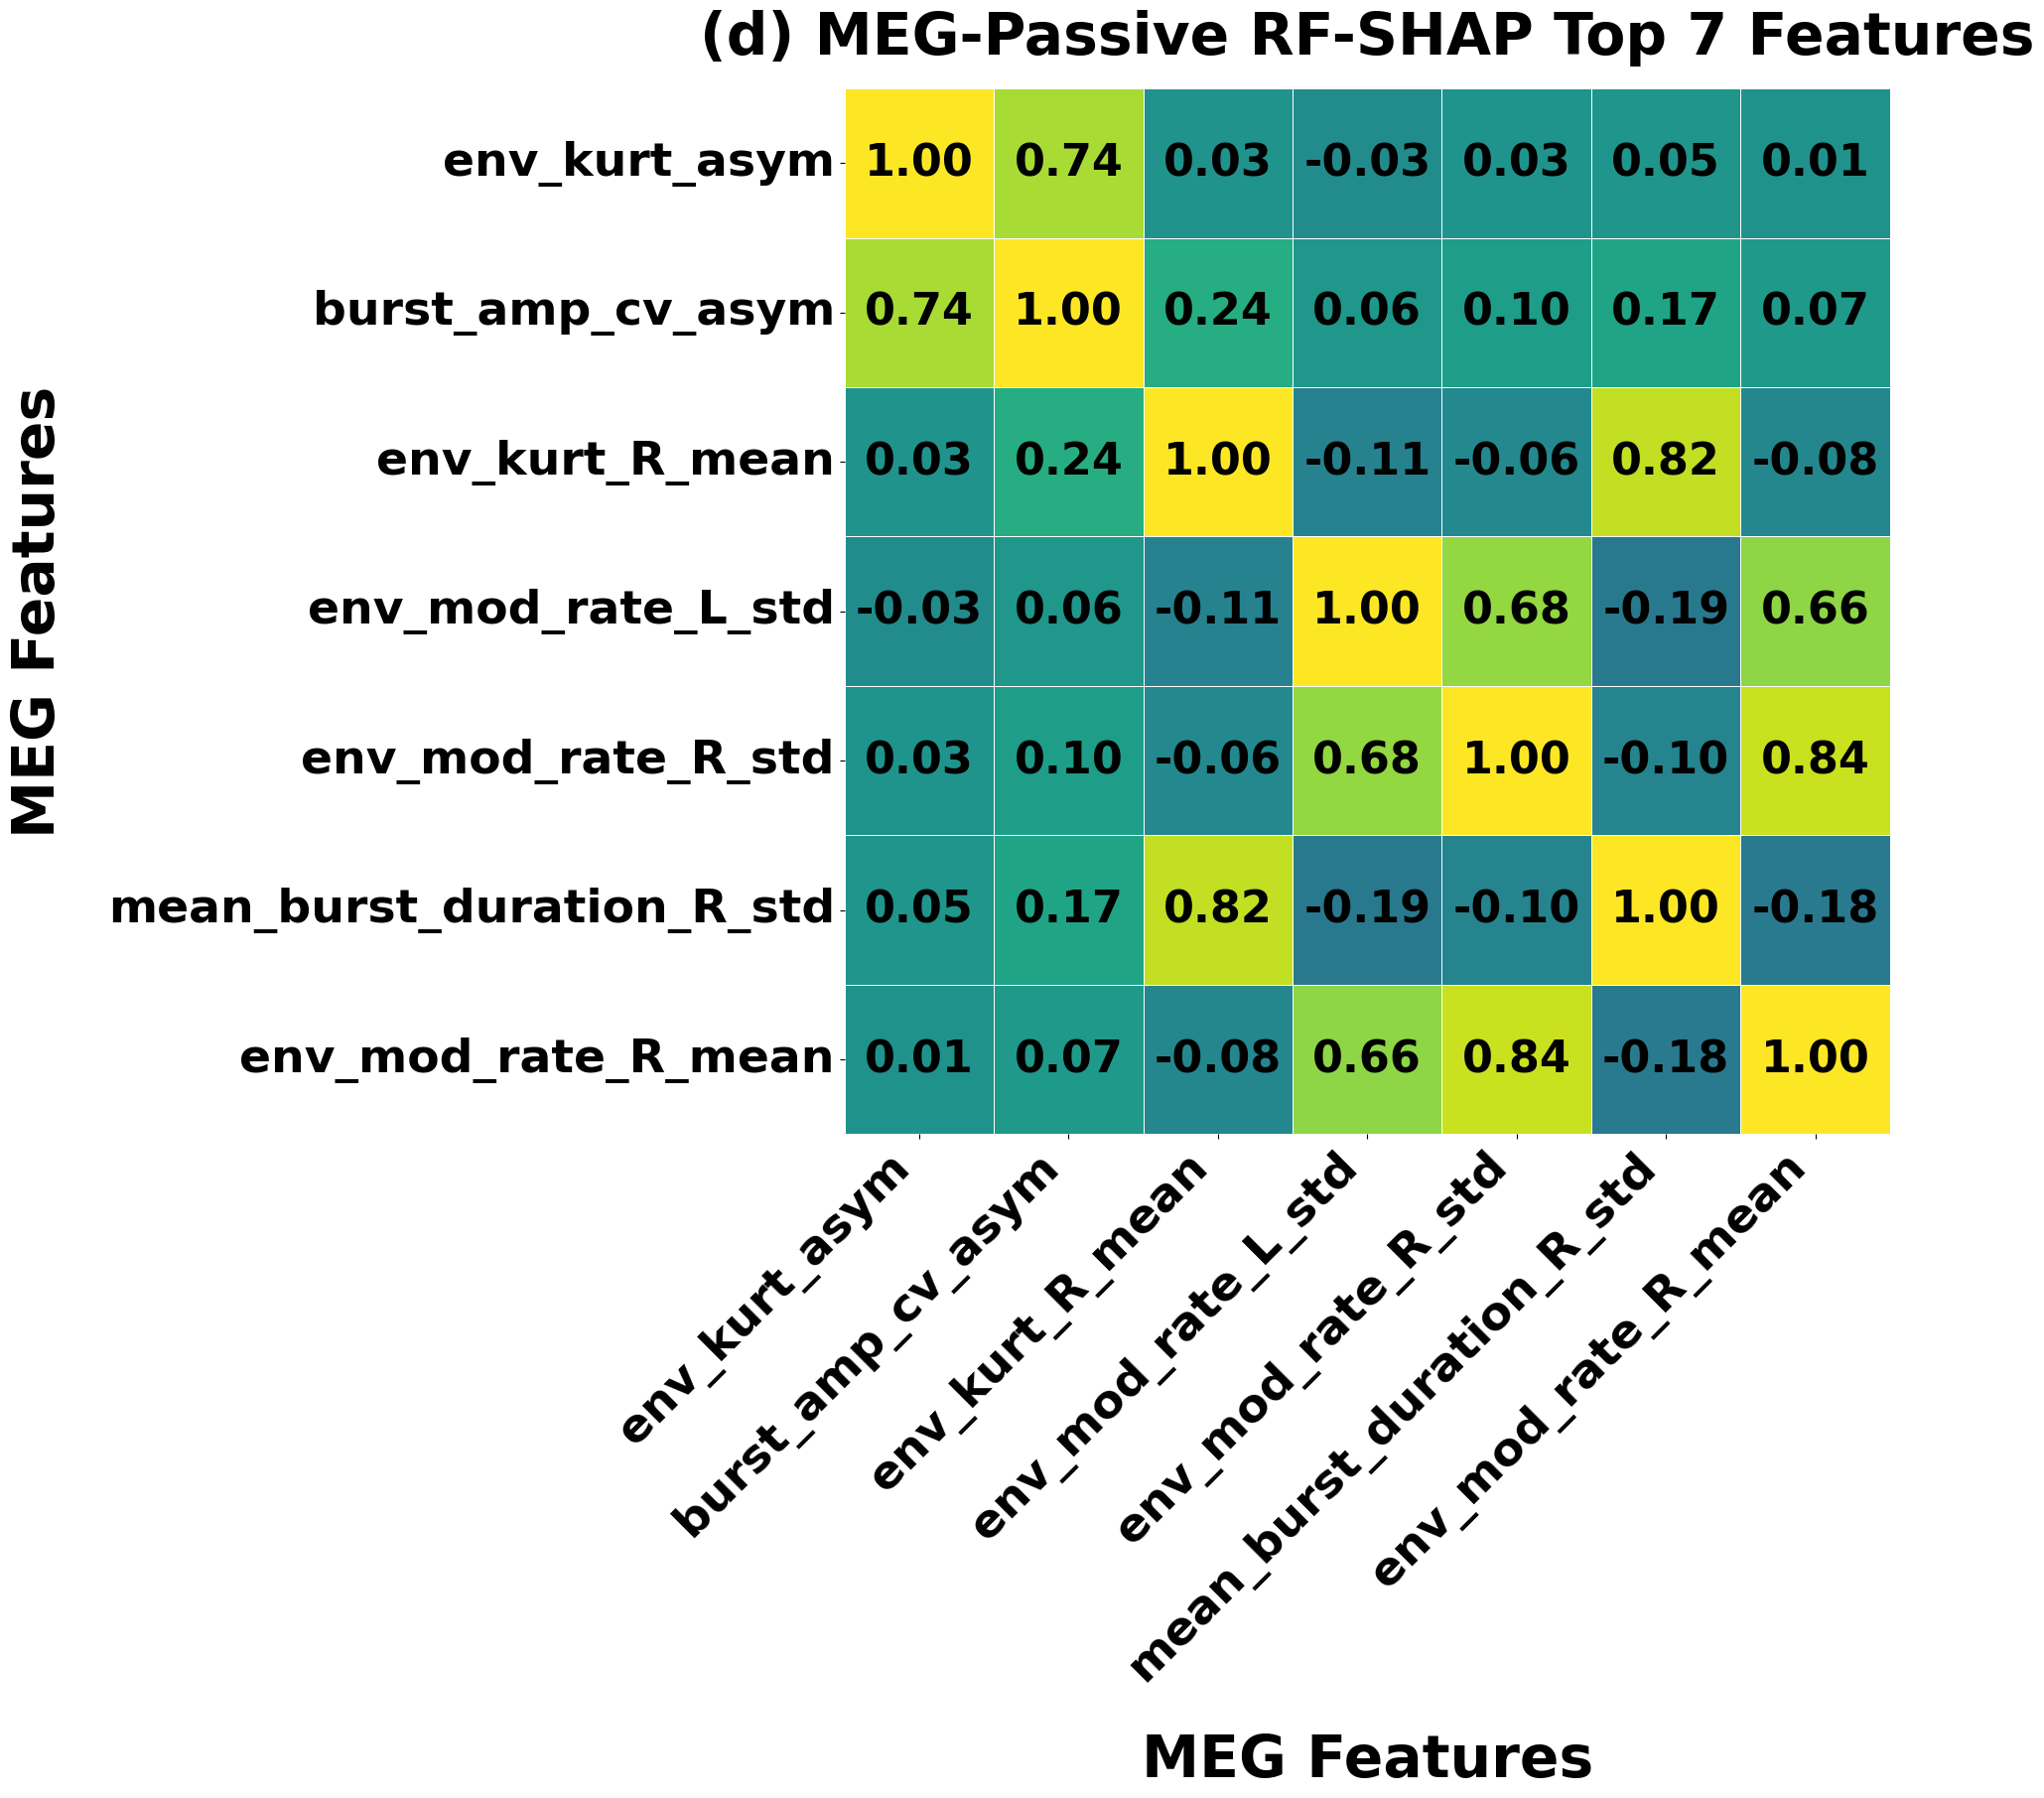

Saved Successfully!
/content/correlation_figures/a) MEG-Passive Top 7.svg
/content/correlation_figures/a) MEG-Passive Top 7.pdf


In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os
from google.colab import files

# ============================================================
# Global plotting settings (IEEE JBHI Publication Style)
# ============================================================
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# meg features
# ============================================================
meg = final_meg_df.iloc[:, :-1].copy()

# ============================================================
# Correlation matrix
# ============================================================
corr = meg.corr()
cross_corr = corr.loc[meg.columns]

# ============================================================
# Output folder
# ============================================================
FIG_DIR = "/content/correlation_figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(
    figsize=(20, 18),
    constrained_layout=True
)

sns.heatmap(
    cross_corr,
    annot=True,
    fmt=".2f",

    # Light diverging color palette
    cmap="viridis",

    # Fixed correlation range
    center=0,
    vmin=-1,
    vmax=1,

    # Heatmap appearance
    square=True,
    linewidths=0.7,
    linecolor="white",

    # No colorbar
    cbar=False,

    # Annotation settings
    annot_kws={
        "size": 32,
        "weight": "semibold",
        "color": "black"
    },

    ax=ax
)

# ============================================================
# Tick labels
# ============================================================
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
    fontsize=34,
    fontweight="semibold"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=34,
    fontweight="semibold"
)

# ============================================================
# Axis labels
# ============================================================
ax.set_xlabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

ax.set_ylabel(
    "MEG Features",
    fontsize=42,
    fontweight="semibold",
    labelpad=30
)

# ============================================================
# Title
# ============================================================
ax.set_title(
    "(d) MEG-Passive RF-SHAP Top 7 Features",
    fontsize=42,
    fontweight="bold",
    pad=25
)

# ============================================================
# Save Figure
# ============================================================
svg_path = os.path.join(
    FIG_DIR, "a) MEG-Passive Top 7.svg"
)

pdf_path = os.path.join(
    FIG_DIR, "a) MEG-Passive Top 7.pdf"
)

plt.savefig(
    svg_path,
    format="svg",
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    pdf_path,
    format="pdf",
    bbox_inches="tight",
    transparent=True
)

plt.show()
plt.close(fig)

print("Saved Successfully!")
print(svg_path)
print(pdf_path)

In [4]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Combining all four

In [1]:
# 1. Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd

df_acoustic_top7 = pd.read_csv('/content/drive/MyDrive/Acoustic-subject-level-dataset_top7.csv')
df_acoustic_top7 = df_acoustic_top7.drop(columns=['Participant_ID'])
print(df_acoustic_top7.shape)
print(df_acoustic_top7.head())

(193, 8)
       RPDE  Degree-voice breaks  Delta2  Delta3  Delta11  MFCC5   spread1  \
0  0.428488                  0.0     0.0     0.0      0.0    0.0 -4.239926   
1  0.542488                  0.0     0.0     0.0      0.0    0.0 -4.519291   
2  0.332247                  0.0     0.0     0.0      0.0    0.0 -7.226125   
3  0.498593                  0.0     0.0     0.0      0.0    0.0 -5.632290   
4  0.470775                  0.0     0.0     0.0      0.0    0.0 -5.523149   

   Status  
0       1  
1       1  
2       0  
3       1  
4       1  


In [3]:
import pandas as pd

final_meg_rest = pd.read_csv('/content/drive/MyDrive/final_meg-rest(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_rest.shape)
print(final_meg_rest.head())

Loaded data shape: (127, 8)
   ibi_cv_asym  ibi_cv_L_std  mean_burst_duration_R_std  \
0     0.002893      0.048081                   0.002407   
1    -0.018062      0.085531                   0.005160   
2    -0.002573      0.032173                   0.001270   
3     0.001531      0.044880                   0.003106   
4     0.023834      0.142267                   0.004734   

   mean_burst_duration_asym  burst_dur_cv_R_std  burst_dur_cv_L_std  \
0                  0.009156            0.040693            0.055777   
1                 -0.005581            0.048648            0.052883   
2                  0.007325            0.030995            0.046488   
3                  0.005372            0.042429            0.049082   
4                  0.014897            0.044595            0.053040   

   ibi_cv_R_std  PD_Label_Combined  
0      0.043907                  0  
1      0.086747                  0  
2      0.032718                  0  
3      0.044973                  1  
4    

In [4]:
import pandas as pd

final_meg_go = pd.read_csv('/content/drive/MyDrive/final_meg-go(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_go.shape)
print(final_meg_go.head())


Loaded data shape: (127, 8)
   env_kurt_R_mean  env_kurt_R_std  env_kurt_L_mean  env_kurt_L_std  \
0         5.749049       15.894836         5.962378       17.165772   
1         4.459546        7.184608         4.390848        6.578943   
2         1.161476        0.718562         1.885349        1.714298   
3         1.138575        0.699601         1.365950        0.817770   
4     18283.789736     4480.567058     18277.357293     4487.602704   

   burst_dur_cv_L_std  env_mod_rate_L_std  env_skew_L_mean  PD_Label_Combined  
0        4.938551e-02            0.244843         1.123760                  0  
1        1.147524e-01            0.117228         1.400286                  0  
2        5.040195e-02            0.275503         0.953293                  0  
3        4.311462e-02            0.460356         0.920828                  1  
4        1.043683e-16            0.064449       129.243639                  1  


In [5]:
import pandas as pd

final_meg_passive = pd.read_csv('/content/drive/MyDrive/final_meg-passive(par)_top7_rfc+shap_10-fold_analysis_last_column.csv')

print("Loaded data shape:", final_meg_passive.shape)
print(final_meg_passive.head())

Loaded data shape: (127, 8)
   env_kurt_asym  burst_amp_cv_asym  env_kurt_R_mean  env_mod_rate_L_std  \
0      -0.076816           0.013925         2.510726            0.296017   
1      -0.053170          -0.011675         2.189911            0.076190   
2       0.073234           0.010955         1.217854            0.413152   
3       0.077393           0.027533         1.394646            0.467633   
4       0.022059           0.005688         1.268945            0.309523   

   env_mod_rate_R_std  mean_burst_duration_R_std  env_mod_rate_R_mean  \
0            0.312178                   0.002180             0.421821   
1            0.063898                   0.012065             0.208876   
2            0.278854                   0.001874             0.462511   
3            0.511813                   0.003089             0.637478   
4            0.341810                   0.004726             0.295681   

   PD_Label_Combined  
0                  0  
1                  0  
2      

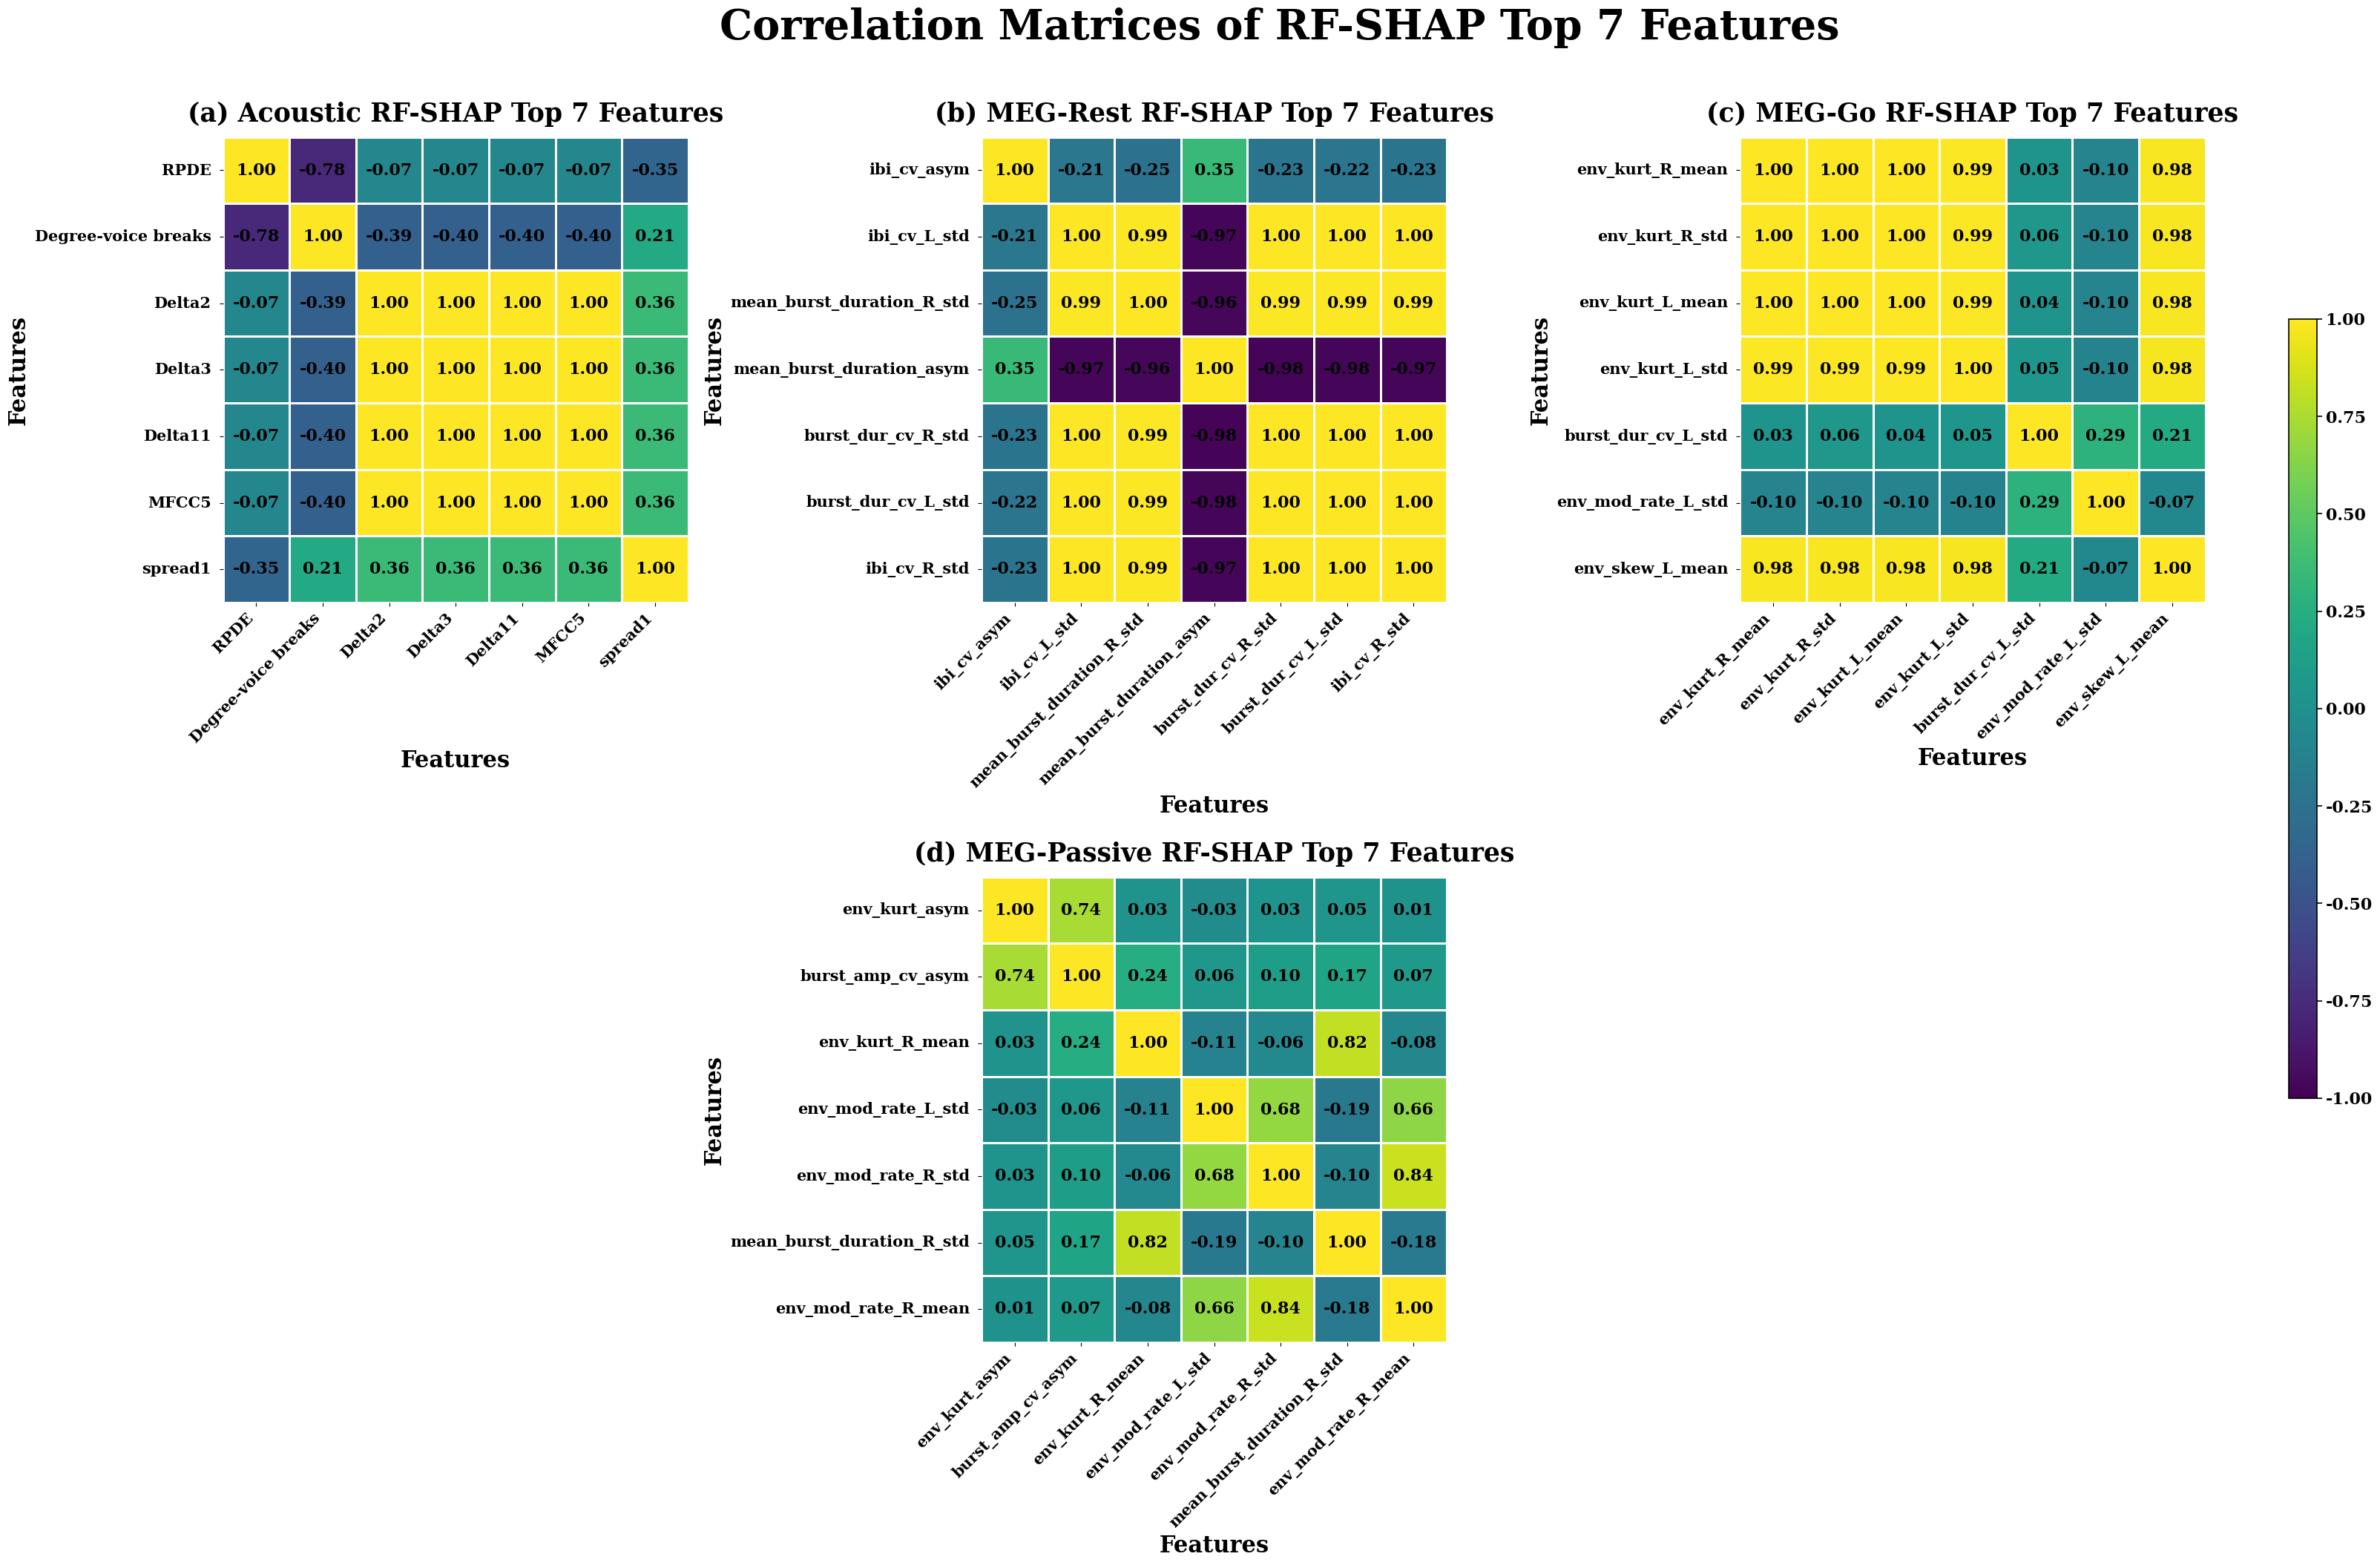

Saved Successfully!
/content/correlation_figures/Combined_Correlation.pdf
/content/correlation_figures/Combined_Correlation.svg


In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import FormatStrFormatter
import os
from google.colab import files

# ============================================================
# Global plotting settings (IEEE JBHI Style)
# ============================================================

plt.rcParams["font.family"] = "serif"
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

# ============================================================
# Acoustic Features
# ============================================================

acoustic = df_acoustic_top7.iloc[:, :-1].copy()

# ============================================================
# MEG Feature DataFrames
# ============================================================

rest_meg = final_meg_rest.iloc[:, :-1].copy()

go_meg = final_meg_go.iloc[:, :-1].copy()

passive_meg = final_meg_passive.iloc[:, :-1].copy()

# ============================================================
# Correlation Matrices
# ============================================================

corr_acoustic = acoustic.corr()

corr_rest = rest_meg.corr()

corr_go = go_meg.corr()

corr_passive = passive_meg.corr()

# ============================================================
# Output Folder
# ============================================================

FIG_DIR = "/content/correlation_figures"

os.makedirs(FIG_DIR, exist_ok=True)

# ============================================================
# Create 2 × 3 Figure
#
# (a) Acoustic       (b) MEG-Rest       (c) MEG-Go
#
#                    (d) MEG-Passive
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(32, 21),
    constrained_layout=False
)

# ============================================================
# Overall Figure Title
# ============================================================

fig.suptitle(
    "Correlation Matrices of RF-SHAP Top 7 Features",
    fontsize=40,
    fontweight="bold",
    y=0.95
)

# ============================================================
# Individual Heatmap Titles
# ============================================================

titles = [
    "(a) Acoustic RF-SHAP Top 7 Features",
    "(b) MEG-Rest RF-SHAP Top 7 Features",
    "(c) MEG-Go RF-SHAP Top 7 Features",
    "(d) MEG-Passive RF-SHAP Top 7 Features"
]

# ============================================================
# Correlation matrices
# ============================================================

corr_list = [
    corr_acoustic,
    corr_rest,
    corr_go,
    corr_passive
]

# ============================================================
# Axes arrangement
# ============================================================

plot_axes = [
    axes[0, 0],   # (a)
    axes[0, 1],   # (b)
    axes[0, 2],   # (c)
    axes[1, 1]    # (d) centered
]

# Hide unused bottom-left and bottom-right axes
axes[1, 0].axis("off")
axes[1, 2].axis("off")

# ============================================================
# Shared Colorbar
# ============================================================

cbar_ax = fig.add_axes(
    [0.925, 0.25, 0.012, 0.50]
)

# ============================================================
# Plot Heatmaps
# ============================================================

for i, (ax, corr_matrix, title) in enumerate(
    zip(plot_axes, corr_list, titles)
):

    sns.heatmap(

        corr_matrix,

        # ----------------------------------------------------
        # Values
        # ----------------------------------------------------
        annot=True,

        fmt=".2f",

        # ----------------------------------------------------
        # Color
        # ----------------------------------------------------
        cmap="viridis",

        center=0,

        # IMPORTANT:
        # Same scale for all four correlation heatmaps
        vmin=-1.0,

        vmax=1.0,

        # ----------------------------------------------------
        # Grid
        # ----------------------------------------------------
        square=True,

        linewidths=0.8,

        linecolor="white",

        # ----------------------------------------------------
        # Annotation formatting
        # ----------------------------------------------------
        annot_kws={
            "size": 16,
            "weight": "semibold",
            "color": "black"
        },

        # ----------------------------------------------------
        # Shared colorbar
        # ----------------------------------------------------
        cbar=(i == 3),

        cbar_ax=cbar_ax if i == 3 else None,

        ax=ax
    )

    # ========================================================
    # Individual Heatmap Title
    # ========================================================

    ax.set_title(
        title,
        fontsize=25,
        fontweight="bold",
        pad=15
    )

    # ========================================================
    # Axis Labels
    # ========================================================

    ax.set_xlabel(
        "Features",
        fontsize=22,
        fontweight="semibold"
    )

    ax.set_ylabel(
        "Features",
        fontsize=22,
        fontweight="semibold"
    )

    # ========================================================
    # X-axis tick labels
    # ========================================================

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        ha="right",
        fontsize=15,
        fontweight="semibold"
    )

    ax.tick_params(
        axis="x",
        pad=4
    )

    # ========================================================
    # Y-axis tick labels
    # ========================================================

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0,
        fontsize=15,
        fontweight="semibold"
    )

    ax.tick_params(
        axis="y",
        pad=8
    )

# ============================================================
# Colorbar Formatting
# ============================================================

# Exact correlation ticks
cbar_ax.set_yticks([
    -1.00,
    -0.75,
    -0.50,
    -0.25,
     0.00,
     0.25,
     0.50,
     0.75,
     1.00
])

# Exactly two decimal places
cbar_ax.yaxis.set_major_formatter(
    FormatStrFormatter("%.2f")
)

cbar_ax.tick_params(
    labelsize=16,
    width=1.2,
    length=5,
    direction="out"
)

for tick in cbar_ax.get_yticklabels():
    tick.set_fontweight("semibold")

# Colorbar border
for spine in cbar_ax.spines.values():
    spine.set_linewidth(1.2)

# ============================================================
# Layout
# ============================================================

plt.subplots_adjust(
    left=0.055,
    right=0.89,
    bottom=0.06,
    top=0.90,
    wspace=0.63,
    hspace=0.30
)

# ============================================================
# Save
# ============================================================

pdf_path = os.path.join(
    FIG_DIR,
    "Combined_Correlation.pdf"
)

svg_path = os.path.join(
    FIG_DIR,
    "Combined_Correlation.svg"
)

plt.savefig(
    pdf_path,
    format="pdf",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.savefig(
    svg_path,
    format="svg",
    dpi=600,
    bbox_inches="tight",
    transparent=True
)

plt.show()

plt.close(fig)

print("Saved Successfully!")
print(pdf_path)
print(svg_path)

In [23]:
files.download(svg_path)
files.download(pdf_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>